In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import matplotlib

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

sns.set_context("paper", font_scale=2.5, rc={"axes.labelsize":40})

In [2]:
data_gwtc4 = np.load("./hierarchical/pSEOB/pseob_hier.npz")
data_gwtc3 = np.load("./hierarchical/pSEOB_GWTC3/pseob_hier_GWTC3.npz")

mu0_gwtc4 = data_gwtc4['mu_domega_220']
mu1_gwtc4 = data_gwtc4['mu_dtau_220']
sigma0_gwtc4 = data_gwtc4['sigma_domega_220']
sigma1_gwtc4 = data_gwtc4['sigma_dtau_220']
rho_gwtc4  = data_gwtc4['rho']

mu0_gwtc3 = data_gwtc3['mu_domega_220']
mu1_gwtc3 = data_gwtc3['mu_dtau_220']
sigma0_gwtc3 = data_gwtc3['sigma_domega_220']
sigma1_gwtc3 = data_gwtc3['sigma_dtau_220']
rho_gwtc3  = data_gwtc3['rho']

## Plots

In [3]:
from pesummary.core.plots.bounded_1d_kde import bounded_1d_kde
from pesummary.core.plots.bounded_2d_kde import Bounded_2d_kde

# =========================================================
# Build the combined DataFrame (uses your existing arrays)
# =========================================================
Mu_actual    = np.zeros(2)
sigma_actual = [0.001, 0.004]
rho_actual   = 0.0

# GWTC-3
Post_samples = np.zeros([len(mu0_gwtc3), 5])
Post_samples[:, 0] = mu0_gwtc3
Post_samples[:, 1] = mu1_gwtc3
Post_samples[:, 2] = sigma0_gwtc3
Post_samples[:, 3] = sigma1_gwtc3
Post_samples[:, 4] = rho_gwtc3
dfA = pd.DataFrame.from_records(Post_samples).rename({
    0: r"$\mu_{\delta \hat{f}_{220}}$",
    1: r"$\mu_{\delta \hat{\tau}_{220}}$",
    2: r"$\sigma_{\delta \hat{f}_{220}}$",
    3: r"$\sigma_{\delta \hat{\tau}_{220}}$",
    4: r"$\rho_{\delta \hat{f}_{220}\delta \hat{\tau}_{220}}$"
}, axis="columns")

# GWTC-4
Post_samples = np.zeros([len(mu0_gwtc4), 5])
Post_samples[:, 0] = mu0_gwtc4
Post_samples[:, 1] = mu1_gwtc4
Post_samples[:, 2] = sigma0_gwtc4
Post_samples[:, 3] = sigma1_gwtc4
Post_samples[:, 4] = rho_gwtc4
dfB = pd.DataFrame.from_records(Post_samples).rename({
    0: r"$\mu_{\delta \hat{f}_{220}}$",
    1: r"$\mu_{\delta \hat{\tau}_{220}}$",
    2: r"$\sigma_{\delta \hat{f}_{220}}$",
    3: r"$\sigma_{\delta \hat{\tau}_{220}}$",
    4: r"$\rho_{\delta \hat{f}_{220}\delta \hat{\tau}_{220}}$"
}, axis="columns")

dfA["set"] = "GWTC-3.0"
dfB["set"] = "GWTC-4.0"
df = pd.concat([dfA, dfB], ignore_index=True)

/cvmfs/software.igwn.org/conda/envs/igwn/lib/python3.10/site-packages/pesummary/utils/decorators.py:288: UserWarning: pesummary.core.plots.bounded_1d_kde.bounded_1d_kde has changed to pesummary.utils.bounded_1d_kde.bounded_1d_kde. This may not be supported in future releases. Please update.
  warnings.warn(warning)
/cvmfs/software.igwn.org/conda/envs/igwn/lib/python3.10/site-packages/pesummary/utils/decorators.py:288: UserWarning: pesummary.core.plots.bounded_1d_kde.bounded_1d_kde has changed to pesummary.utils.bounded_1d_kde.bounded_1d_kde. This may not be supported in future releases. Please update.
  warnings.warn(warning)
/cvmfs/software.igwn.org/conda/envs/igwn/lib/python3.10/site-packages/pesummary/utils/decorators.py:288: UserWarning: pesummary.core.plots.bounded_1d_kde.bounded_1d_kde has changed to pesummary.utils.bounded_1d_kde.bounded_1d_kde. This may not be supported in future releases. Please update.
  warnings.warn(warning)
/cvmfs/software.igwn.org/conda/envs/igwn/lib/pyth

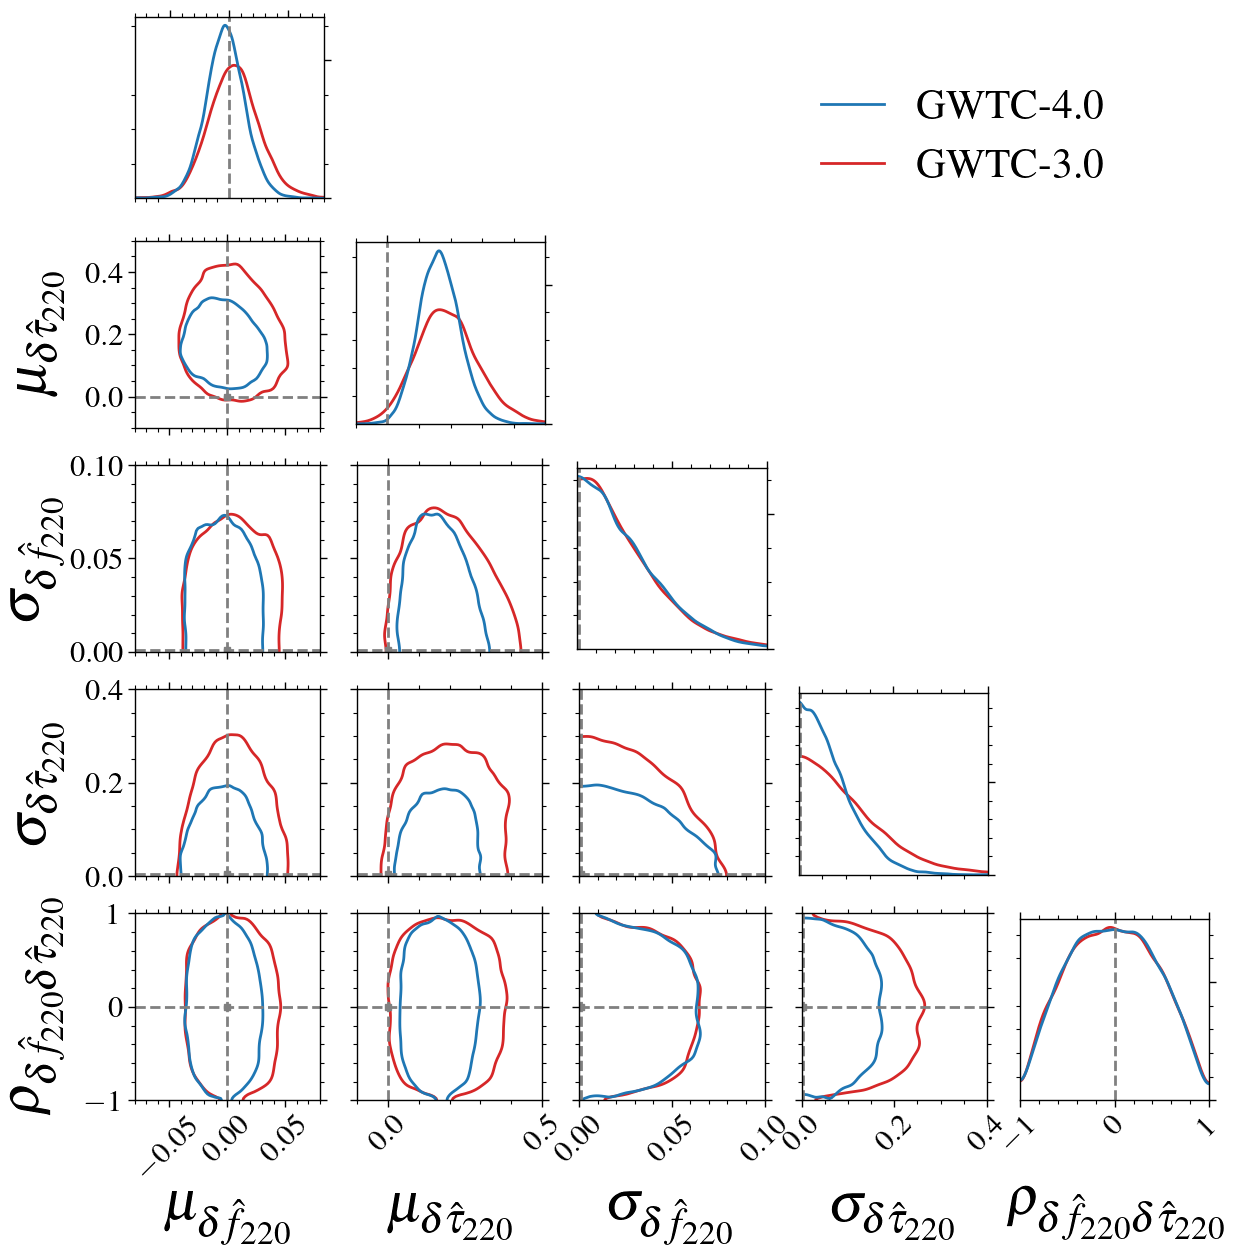

In [4]:
# =========================================================
# Plot settings & helpers
# =========================================================
# --- knobs ---
N1D = 400
N2D = 100
TARGET_MASS = 0.9  # ~90% HDR

CUSTOM_LIMITS = {
    "mu_f"  : (-0.08, 0.08),
    "mu_tau": (-0.1, 0.5),
    "sg_f"  : (0.0, 0.1),
    "sg_tau": (0.0, 0.4),
    "rho"   : (-1.0, 1.0),
}

# labels
mu_f_lbl   = r"$\mu_{\delta \hat{f}_{220}}$"
mu_tau_lbl = r"$\mu_{\delta \hat{\tau}_{220}}$"
sg_f_lbl   = r"$\sigma_{\delta \hat{f}_{220}}$"
sg_tau_lbl = r"$\sigma_{\delta \hat{\tau}_{220}}$"
rho_lbl    = r"$\rho_{\delta \hat{f}_{220}\delta \hat{\tau}_{220}}$"

vars_order = [mu_f_lbl, mu_tau_lbl, sg_f_lbl, sg_tau_lbl, rho_lbl]
sigma_like = {sg_f_lbl, sg_tau_lbl}
palette    = {"GWTC-3.0": "#d62728", "GWTC-4.0": "#1f77b4"}
hue_order  = ["GWTC-3.0", "GWTC-4.0"]

# map simple keys -> DF labels
key_to_lbl = {
    "mu_f": mu_f_lbl, "mu_tau": mu_tau_lbl,
    "sg_f": sg_f_lbl, "sg_tau": sg_tau_lbl, "rho": rho_lbl
}
lbl_to_key = {v: k for k, v in key_to_lbl.items()}

# Estimator bounds (NOT plot limits)
def est_bounds(var_label):
    if var_label in sigma_like:
        return (0.0, None)     # sigma > 0
    if var_label == rho_lbl:
        return (-1.0, 1.0)     # correlation
    return (None, None)        # mus unbounded

# Axis limits: use CUSTOM_LIMITS verbatim
def axis_limits_for(var_label):
    lo, hi = CUSTOM_LIMITS[lbl_to_key[var_label]]
    if hi <= lo: hi = lo + 1e-6
    return (lo, hi)

axis_limits = {v: axis_limits_for(v) for v in vars_order}
grids_1d = {v: np.linspace(*axis_limits[v], N1D) for v in vars_order}
grids_2d = {v: np.linspace(*axis_limits[v], N2D) for v in vars_order}

# =========================================================
# Plot: PairGrid with bounded KDEs
# =========================================================
g = sns.PairGrid(df, vars=vars_order, hue="set", diag_sharey=False,
                 hue_order=hue_order, corner=True, palette=palette)


# Replace diagonal axes with new, independent ones
for i in range(len(g.x_vars)):
    old_ax = g.axes[i, i]
    fig = g.fig

    # Get its position in figure coordinates
    pos = old_ax.get_position()

    # Remove the old shared axis
    old_ax.remove()

    # Create a new axis at the same position (not sharing y with others)
    new_ax = fig.add_axes(pos)
    g.axes[i, i] = new_ax

    # Clean up completely

    if i != len(g.x_vars) - 1:
        new_ax.set_xlabel("")                      # no x label
        new_ax.tick_params(axis="x", bottom=False, labelbottom=False)
    new_ax.set_ylabel("")                      # no y label
    new_ax.tick_params(axis="y", left=False, labelleft=False)
    new_ax.spines["left"].set_visible(True)
    new_ax.spines["right"].set_visible(True)
    new_ax.spines["top"].set_visible(True)

# ---------- Diagonals: bounded 1D KDEs, normalized on panel range ----------

# --- Diagonals: bounded 1D KDEs, normalized on panel range ---
diag_max_per_var = {}

for i, var in enumerate(g.x_vars):
    ax = g.axes[i, i]
    xg = grids_1d[var]
    xlow, xhigh = est_bounds(var)

    xnorm = np.linspace(*axis_limits[var], max(512, 2*N1D))  # for area norm

    panel_max = 0.0
    for label, sub in df.groupby("set", sort=False):
        x = sub[var].to_numpy()
        x = x[np.isfinite(x)]
        if x.size < 2:
            continue

        kde = bounded_1d_kde(x, xlow=xlow, xhigh=xhigh, method="Reflection")
        try:
            yg   = kde(xg)
            ynrm = kde(xnorm)
        except TypeError:
            yg   = kde.pdf(xg)
            ynrm = kde.pdf(xnorm)

        # normalize so area over the panel range = 1 (unchanged)
        area = np.trapz(ynrm, xnorm)
        if np.isfinite(area) and area > 0:
            yg = yg / area

        if np.any(np.isfinite(yg)):
            panel_max = max(panel_max, float(np.nanmax(yg)))

        ax.plot(xg, yg, lw=2, color=palette[label], label=label)

    # <-- key change: give THIS panel its own y-limit
    if panel_max <= 0 or not np.isfinite(panel_max):
        panel_max = 1.0
    ax.set_ylim(0.0, 1.05 * panel_max)

    ax.set_xlim(*axis_limits[var])
    if i == len(g.x_vars) - 1:
        ax.set_xlabel(var, labelpad=20)
    ax.set_ylabel("")
    ax.spines["left"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["top"].set_visible(True)
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.tick_params(axis="x", rotation=45)

# ---------- Lower triangle: bounded 2D KDEs ----------
for r, yvar in enumerate(g.y_vars):
    for c, xvar in enumerate(g.x_vars):
        if r <= c:
            continue
        ax = g.axes[r, c]

        Xg = grids_2d[xvar]; Yg = grids_2d[yvar]
        X, Y = np.meshgrid(Xg, Yg, indexing="xy")

        xlow, xhigh = est_bounds(xvar)
        ylow, yhigh = est_bounds(yvar)

        for label, sub in df.groupby("set", sort=False):
            x = sub[xvar].to_numpy(); y = sub[yvar].to_numpy()
            m = np.isfinite(x) & np.isfinite(y)
            x, y = x[m], y[m]
            if len(x) < 5:
                continue

            samples = np.vstack([x, y])  # (2, N)
            kde2 = Bounded_2d_kde(samples,
                                  xlow=xlow, xhigh=xhigh,
                                  ylow=ylow, yhigh=yhigh)

            XY = np.vstack([X.ravel(), Y.ravel()])
            try:
                Z = kde2(XY).reshape(X.shape)
            except TypeError:
                Z = kde2.pdf(XY).reshape(X.shape)

            # ~90% HDR contour
            z = Z.ravel()
            z = z[np.isfinite(z)]
            if z.size == 0:
                continue
            order = np.argsort(z)[::-1]
            z_sorted = z[order]
            cdf = np.cumsum(z_sorted); cdf /= cdf[-1]
            thr = z_sorted[np.searchsorted(cdf, TARGET_MASS, side="left")]

            ax.contour(X, Y, Z, levels=[thr], linewidths=2, colors=[palette[label]])

        ax.set_xlim(*axis_limits[xvar])
        ax.set_ylim(*axis_limits[yvar])
        ax.set_xlabel(xvar)
        ax.set_ylabel(yvar)
        ax.tick_params(axis="x", rotation=45)
        ax.spines["left"].set_visible(True)
        ax.spines["right"].set_visible(True)
        ax.spines["top"].set_visible(True)
    
# ---------- Legend ----------
handles = [plt.Line2D([], [], color=palette[h], lw=2) for h in hue_order]
g.fig.legend(handles, hue_order, loc="upper left", bbox_to_anchor=(0.62, 0.95), title=None, frameon=False, fontsize=30, reverse=True)

# ---------- Truth lines & marker ----------
truth_by_name = {
    mu_f_lbl:   Mu_actual[0],
    mu_tau_lbl: Mu_actual[1],
    sg_f_lbl:   sigma_actual[0],
    sg_tau_lbl: sigma_actual[1],
    rho_lbl:    rho_actual,
}
for i, v in enumerate(vars_order):
    g.axes[i, i].axvline(truth_by_name[v], ls='--', lw=2, c='gray')

idx = {v: i for i, v in enumerate(vars_order)}
for yvar in g.y_vars:
    for xvar in g.x_vars:
        r, c = idx[yvar], idx[xvar]
        if r <= c:
            continue
        ax = g.axes[r, c]
        xv = truth_by_name[xvar]; yv = truth_by_name[yvar]
        ax.axvline(xv, ls='--', lw=2, c='gray')
        ax.axhline(yv, ls='--', lw=2, c='gray')
        ax.plot(xv, yv, marker='s', color='gray')

g.fig.align_labels()
g.fig.subplots_adjust(wspace=0.2, hspace=0.2)

os.makedirs("./plots", exist_ok=True)
plt.savefig("./plots/hier_corner_pSEOB_GWTC3_GWTC4.pdf", bbox_inches='tight', dpi=300)